# Part 5h: the rescue rate moved after 2021. Can a model keep up, and what does it do to the headline?

The state hindcast (Part 5g) found that the rescue rate rose after 2021: 3.9 and 4.5 percent of 2022 and 2023 lapses were re-subsidized within three years, against about 1 percent before. A reviewer will call that **non-stationarity** and ask three things. Is it just a change in the mix of properties? Can a model that is updated as time passes anticipate it? And what would the headline be if the recent rate persisted? (`src/rescue_drift.py`)

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import preservation as P
import rescue_drift as D
from viz import apply_style, SERIES, save_figure, BASELINE, INK_2, dot

apply_style()
pd.set_option("display.width", 220)
ev = P.build_events()
ev["period"] = pd.cut(ev.Y, [2010, 2015, 2020, 2023], labels=["2011-15", "2016-20", "2021-23"])

## 1. Is it the mix of properties?

If the rise were a change in what lapses (more HUD properties, bigger properties) it would show up as a change in composition and the model would absorb it. It does not: the rise is inside the HOME-only group, which is 93 percent of lapses.

In [2]:
comp = ev.groupby("period", observed=True).agg(lapses=("Y", "size"), rescue_rate_pct=("resub_3y", lambda s: 100 * s.mean()), median_units=("total_units", "median"), hud_share_pct=("g_hud", lambda s: 100 * s.mean()))
display(comp.round(2))
grp = ev[ev.group.isin(["home_only", "hud"])].groupby(["group", "period"], observed=True).agg(lapses=("Y", "size"), rescue_rate_pct=("resub_3y", lambda s: 100 * s.mean()))
display(grp.round(2))
yearly = ev.groupby("Y").resub_3y.agg(rate=lambda s: 100 * s.mean(), lapses="size", rescued="sum")
display(yearly.round(2).T)

,lapses,rescue_rate_pct,median_units,hud_share_pct
period,,,,
2011-15,5233,1.11,2.0,6.06
2016-20,4803,0.85,3.0,5.14
2021-23,2786,3.23,4.0,6.96


lapses  rescue_rate_pct
group     period                          
home_only 2011-15    4898             0.43
          2016-20    4521             0.60
          2021-23    2513             2.63
hud       2011-15     317            11.04
          2016-20     247             5.67
          2021-23     194            10.82

Y,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0
rate,0.31,0.73,2.08,1.39,1.3,1.04,0.78,1.1,0.45,0.82,1.43,3.94,4.49
lapses,1270.00,961.00,914.00,1008.00,1080.0,1053.00,896.00,1000.0,884.00,970.00,979.00,938.00,869.00
rescued,4.00,7.00,19.00,14.00,14.0,11.00,7.00,11.0,4.00,8.00,14.00,37.00,39.00


## 2. Can a model that is updated in real time anticipate it?

For lapses in year T a forecaster knows only outcomes of lapses through T-3, because a lapse needs three years to be labeled. Five methods are refit for every T from 2019 to 2023.

In [3]:
rt = D.real_time(ev)
summ = D.summary(rt).sort_values("log_loss")
display(summ.round(4))
pred = rt.pivot(index="method", columns="year", values="predicted") * 100
obs = rt.groupby("year")["observed"].first() * 100
display(pd.concat([pred.round(2), pd.DataFrame(obs.round(2)).T.rename(index={"observed": "OBSERVED"})]))

,log_loss,brier,mean_abs_calibration_error
method,,,
static,0.0983,0.0213,0.0133
recency weighted,0.1002,0.0214,0.0142
year trend,0.1017,0.0223,0.0183
intercept shift,0.1027,0.0215,0.0152
constant rate,0.1157,0.0217,0.0161


year,2019,2020,2021,2022,2023
constant rate,1.17,0.92,0.95,0.80,0.65
intercept shift,1.44,0.93,1.19,0.88,1.07
recency weighted,1.31,1.04,1.29,0.97,1.37
static,1.19,0.98,1.22,1.08,1.65
year trend,2.83,1.60,1.95,1.14,1.61
OBSERVED,0.45,0.82,1.43,3.94,4.49


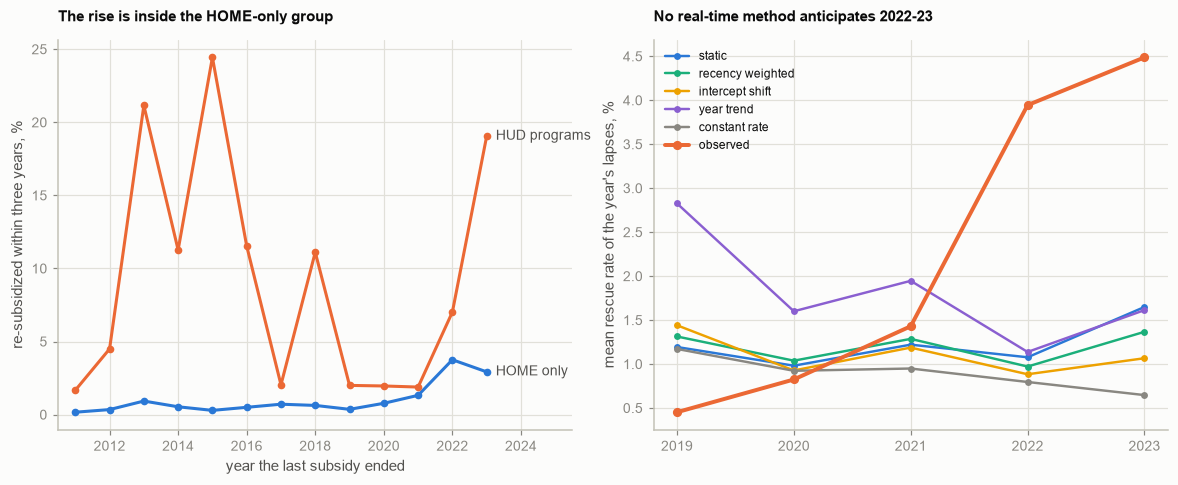

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10.6, 4.3))
ax = axs[0]
for g, c, lab in (("home_only", SERIES[0], "HOME only"), ("hud", SERIES[1], "HUD programs")):
    s = ev[ev.group == g].groupby("Y").resub_3y.mean() * 100
    ax.plot(s.index, s.values, color=c, lw=2.0, marker="o", ms=4)
    ax.annotate(lab, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("year the last subsidy ended"); ax.set_ylabel("re-subsidized within three years, %"); ax.set_xlim(2010.5, 2025.5)
ax.set_title("The rise is inside the HOME-only group", fontsize=10, loc="left")
ax = axs[1]
colors = {"static": SERIES[0], "recency weighted": SERIES[2], "intercept shift": SERIES[3], "year trend": "#8a5fd0", "constant rate": "#898781"}
for k, c in colors.items():
    ax.plot(pred.columns, pred.loc[k], color=c, lw=1.6, label=k, marker="o", ms=3.5)
ax.plot(obs.index, obs.values, color=SERIES[1], lw=2.6, marker="o", ms=5, label="observed")
ax.set_xticks(list(pred.columns)); ax.set_ylabel("mean rescue rate of the year's lapses, %"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("No real-time method anticipates 2022-23", fontsize=10, loc="left")
save_figure(fig, "59_rescue_drift", part="05_preservation")
plt.show()

## 3. What the headline would be if the recent rate persisted

The scored properties get the fitted logistic regression with its intercept moved so that it reproduces the 2022-23 rescue rate on those lapses. This is a scenario, not a prediction: nothing in the data says the 2022-23 rate will last.

In [5]:
import uncertainty as U
prep = U.prepare(); pt = U.point_estimates()
p_recent, delta, rate = D.recent_rate_probabilities(prep["ev"], prep["scored"])
base_p = prep["scored"].p_rescue
print(f"2022-23 observed rescue rate {100 * rate:.2f} %; intercept shift {delta:+.2f} log-odds; mean rescue chance of the scored properties {100 * base_p.mean():.2f} % -> {100 * p_recent.mean():.2f} %")
lb0, ub0 = U._unrescued(prep["scored"], base_p); lb1, ub1 = U._unrescued(prep["scored"], p_recent)
print(f"HOME and HUD units not rescued: {lb0:,.0f} to {ub0:,.0f} -> {lb1:,.0f} to {ub1:,.0f}")
sens = U.sensitivity(prep, pt)                      # includes this case as a standard row
row = sens[sens.case.str.startswith("Rescue chance stays")].iloc[0]
print(f"total: {row.total_low:,.0f} to {row.total_high:,.0f} ({row.change_pct:+.1f} % on the midpoint); headline {sens.total_low.iloc[0]:,.0f} to {sens.total_high.iloc[0]:,.0f}")
display(sens.round(1))
rt.to_csv("outputs/tables/rescue_drift_real_time.csv", index=False)

2022-23 observed rescue rate 4.21 %; intercept shift +0.93 log-odds; mean rescue chance of the scored properties 4.56 % -> 9.95 %
HOME and HUD units not rescued: 294,898 to 352,711 -> 252,415 to 300,927


total: 857,361 to 981,190 (-4.9 % on the midpoint); headline 899,845 to 1,032,975


,case,total_low,total_high,midpoint,change_vs_headline,change_pct
0,Headline (as reported),899844.6,1032974.6,966409.6,0.0,0.0
1,Growth need: low scenario (renting keeps falling),558401.0,691531.1,624966.0,-341443.6,-35.3
2,Growth need: high scenario (renting rises),1179646.1,1312776.1,1246211.1,279801.5,29.0
3,HOME and HUD units: property total (upper boun...,957657.7,1032974.6,995316.2,28906.6,3.0
4,Rescue model: size only,908131.0,1042008.5,975069.8,8660.2,0.9
5,Rescue model: gradient boosting instead of log...,909121.5,1046013.1,977567.3,11157.7,1.2
6,Rescue chance stays at its 2022-23 level,857360.9,981190.3,919275.6,-47134.0,-4.9
7,LIHTC: unadjusted exit share in both cases,960790.7,1032974.6,996882.7,30473.1,3.2
8,Insured mortgages: low case in both,899844.6,1018603.8,959224.2,-7185.4,-0.7
9,Remove possible double count with LIHTC (183 p...,886173.6,1018824.7,952499.2,-13910.4,-1.4


## Findings

**The rise is not a change in the mix of properties.** The rescue rate was 1.11 percent for 2011-15 lapses, 0.85 percent for 2016-20, and 3.23 percent for 2021-23 (3.94 percent in 2022 and 4.49 in 2023). The share of HUD-program lapses (5 to 7 percent) and the median size (2 to 4 units) barely moved. The rise is inside the HOME-only group, 93 percent of lapses, whose rate went from 0.43 and 0.60 percent to 2.63 percent; the HUD-program rate (only about 60 lapses a year, so noisy) was 11.04 percent in 2011-15, dipped to 5.67 percent in 2016-20, and was 10.82 percent in 2021-23.

**No real-time method anticipates it.** Refit every year on the outcomes already labeled (lapses through T-3), the static model, a recency-weighted version, an intercept shift to the latest two years, a year trend, and a constant recent rate all predict 0.7 to 1.7 percent for 2022 and 2023 against 3.9 and 4.5 observed. The simplest method (static) has the best log loss (0.098) and the best average calibration error (1.3 points); the extra machinery does not help, because a jump in the data cannot be learned from the years before it. This is a regime change, probably funding or program rules that the data do not contain, not something to model away.

**So it is treated as a scenario.** If the rescue rate stays at its 2022-23 level (4.21 percent), the fitted model's intercept moves up 0.93 log-odds and the average rescue chance of the scored properties rises from 4.6 to 10.0 percent. HOME and HUD units not rescued fall from 295,000 to 353,000 to **252,000 to 301,000**, and the total from 900,000 to 1,033,000 to **857,000 to 981,000 (-4.9 percent on the midpoint)**. That is the largest modeling-side sensitivity in Part 6b, though still far smaller than the growth scenario. The headline keeps the all-years model, which is the conservative choice (a higher loss), and states the alternative.

**Caveats.** Two high years (76 rescues among 1,807 lapses); the cause is unknown; HUD-program rates are noisy and back near their 2011-15 level, so the rise is mainly a HOME-program story; the intercept shift assumes the size gradient is unchanged, which the hindcast (Part 5g) showed is shaky at the top sizes.